# Seasonality and foreign-guest indices

Step 2 of 3:

1. `Stage 1 Transform.ipynb` — raw Eurostat file → clean nights with flags and **nights per day** (`data/transformed/tour_occ_nin2m_long.csv`);
2. **this notebook** is the **technical reference**: every index with its full definition, the choice of each threshold and the robustness checks; the indices are saved as three files in `data/ready/`;
3. `Stage 3 Analysis.ipynb` — the findings. It reads only the Stage 1 file and computes the indices it needs with the constants settled here, so its numbers match these files.

#### Constants settled here

| Constant | Value | Section |
|---|---|---|
| Volume floor | 100,000 nights a year per series | A1 |
| No clear season | Gini < 0.15 | B4 |
| Gini classes (`GiniClass`) | Low < 0.15 · Medium 0.15–0.33 · High ≥ 0.33 (fixed, the same for every guest group) | B5 |
| Spread ratio (S_R ÷ Gini) | one season ≥ 0.9 · main + secondary 0.6–0.9 · two seasons < 0.6 | B4 |
| Season patterns | Summer season · Winter + summer seasons · Winter season (if 5+ regions) · Year-round; shape groups chosen by silhouette | B5 |
| Foreign effect, main | RME outcome: Flatten ≤ −0.02 · Little effect · Sharpen ≥ +0.02, same sign in 2023 and 2024 | C2 |
| Foreign effect, check | timing effect beyond ±0.01 Gini points, same sign in both years | C2 |

**Changes from the earlier version:** the volume floor is 100,000 nights instead of 10,000 (A1); the Gini classes use fixed cut-offs instead of terciles (B5); summer seasons are no longer split into "short" and "long" — length is what Season75 measures (B5); the four RME types are replaced by three outcomes, because the "off-peak" type is not stable between years and "neutral" mixes different situations (C2, R5); indicators the analysis does not use are removed (seasonality indicator, peak-to-trough ratio, trough month, July–August and winter factors, percentile ranks, top-2-month share, the S_R and AME foreign-effect classes, the geography group columns); intensity and density follow Stage 3's definitions (B6); `AmplitudeClass` is renamed `GiniClass`.

#### Output files (`data/ready/`)

* `tour_occ_nin2m_indices.csv` — one row per region × guest group × period (`2023`, `2024`, `2023-2024`): all indices;
* `tour_occ_nin2m_profiles.csv` — the monthly profiles behind them (share of the year's nights per day, seasonal factor, months in the 75% season);
* `tour_occ_nin2m_foreign_effect.csv` — one row per region × period: the foreign-guest effect measures.

Robustness checks are in the appendix (R1–R5). Needs pandas, numpy, scipy, matplotlib.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.cluster.hierarchy import fcluster, linkage
from scipy.spatial.distance import pdist, squareform

pd.set_option("display.max_rows", 200)
pd.set_option("display.width", 200)

df = pd.read_csv("data/transformed/tour_occ_nin2m_long.csv", encoding="utf-8-sig", keep_default_na=False, na_values=[""])
MONTH_NAMES = ["January", "February", "March", "April", "May", "June", "July", "August",
               "September", "October", "November", "December"]
SHORT = [m[:3] for m in MONTH_NAMES]
T = 12
KEY_SERIES = ["NUTSCode", "Year", "ResidenceCountry"]
RESIDENCES = ["Domestic", "Foreign", "Total"]
monthly = df["Month"] != "Total"

# One row per series (region x year x guest group), the 12 months as columns.
npd = df[monthly].pivot_table(index=KEY_SERIES, columns="Month", values="NightsPerDay").reindex(columns=MONTH_NAMES)
nights = df[monthly].pivot_table(index=KEY_SERIES, columns="Month", values="Value").reindex(columns=MONTH_NAMES)
annual = df[~monthly].set_index(KEY_SERIES)["Value"]
flags = df[monthly].assign(C=df["Flag"].eq("C"), u=df["Flag"].eq("u")).groupby(KEY_SERIES)[["C", "u"]].any()
regions = df.drop_duplicates("NUTSCode").set_index("NUTSCode")[["Region", "NUTSLevel", "ParentRegion", "Country"]]

INK, MUTED, GRIDC = "#0b0b0b", "#52514e", "#e4e3df"
def style(ax, title, ylabel=None):
    ax.set_title(title, loc="left", color=INK, fontsize=12)
    if ylabel:
        ax.set_ylabel(ylabel, color=MUTED)
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color(MUTED)
    ax.tick_params(colors=MUTED)
    ax.grid(axis="y", color=GRIDC, lw=0.8)
    ax.set_axisbelow(True)

print(f"{len(npd):,} series; {len(regions)} regions; years {sorted(df['Year'].unique())}")

2,389 series; 402 regions; years [np.int64(2023), np.int64(2024)]


# A. Usable series and the average profile

## A1. Usable series (`VolumeOK`)

A series (region × year × guest group) is used for the indices when:

* all **12 months are published** (no `:`) and **none is confidential** (`C`);
* it has at least **100,000 nights** in the year. The table below is the evidence: the change of the Gini index from 2023 to 2024, by size of the series. Above 100,000 nights the typical change is about 0.01; in the 30,000–100,000 band it is several times larger, i.e. the profile of a small series is mostly year-to-year noise. The list under the table names every series the rule removes.

Months flagged **`u` (low reliability)** are kept, but the series is marked `LowReliability` (Corse and the French overseas regions) so the findings can show them with caution. `e` (estimated) occurs only in Albania's 2023 values; they are used as published. Volumes, intensity and density (Stage 3, Part 1) use the annual totals of all regions and are not affected by this rule.

In [2]:
MIN_NIGHTS = 100_000
complete = npd.notna().all(axis=1) & ~flags["C"].reindex(npd.index, fill_value=False)
volume_ok = complete & (annual.reindex(npd.index) >= MIN_NIGHTS)
low_rel = flags["u"].reindex(npd.index, fill_value=False)

def gini(y):
    """Gini index of 12 values, covariance form (Fernández-Morales et al. 2016): 0 = flat, 0.917 = one month."""
    y = np.asarray(y, float)
    r = np.empty(T); r[np.argsort(y, kind="stable")] = np.arange(1, T + 1)
    F = r / T
    return 2 * np.mean((y - y.mean()) * (F - F.mean())) / y.mean()

# Evidence for the threshold: change of Gini from 2023 to 2024, by size of the series.
g_y = pd.Series([gini(r) for r in npd[complete].to_numpy()], index=npd.index[complete])
gw = g_y.unstack("Year").dropna()
size = annual.xs(2023, level="Year").reindex(gw.index)
ev = pd.DataFrame({"dGini": (gw[2024] - gw[2023]).abs(),
                   "annual nights": pd.cut(size, [0, 3e3, 1e4, 3e4, 1e5, 1e6, np.inf],
                                           labels=["< 3k", "3k-10k", "10k-30k", "30k-100k", "100k-1m", "> 1m"])})
display(ev.groupby("annual nights", observed=True)["dGini"].agg(series="size", typical_change="median",
                                                                 p90_change=lambda s: s.quantile(0.9)).round(3))
print(f"{int(volume_ok.sum()):,} of {len(npd):,} series usable. Series left out:")
left = pd.DataFrame({"missing or confidential months": ~complete, f"under {MIN_NIGHTS:,} nights": ~(annual.reindex(npd.index) >= MIN_NIGHTS)})[~volume_ok]
left = left.assign(reason=left.apply(lambda r: ", ".join(k for k, v in r.items() if v), axis=1)).reset_index()
left["Region"] = left["NUTSCode"].map(regions["Region"])
display(left.pivot_table(index=["Region", "NUTSCode", "Year"], columns="ResidenceCountry", values="reason", aggfunc="first").fillna(""))

,series,typical_change,p90_change
annual nights,,,
3k-10k,3,0.008,0.008
10k-30k,1,0.012,0.012
30k-100k,8,0.047,0.086
100k-1m,131,0.011,0.031
> 1m,1040,0.007,0.020


2,359 of 2,389 series usable. Series left out:


ResidenceCountry                                           Domestic                                            Foreign
Region                NUTSCode Year                                                                                   
Ciudad de Ceuta       ES63     2023                                                               under 100,000 nights
                               2024            under 100,000 nights                               under 100,000 nights
Ciudad de Melilla     ES64     2023                                                               under 100,000 nights
                               2024                                                               under 100,000 nights
Dytiki Makedonia      EL53     2023                                                               under 100,000 nights
                               2024                                                               under 100,000 nights
Guadeloupe            FRY1     2023  missing or confidential months                     missing or confidential months
Guyane                FRY3     2023  missing or confidential months  missing or confidential months, under 100,000 ...
Liechtenstein         LI       2023            under 100,000 nights                                                   
                               2024            under 100,000 nights                                                   
                      LI0      2023            under 100,000 nights                                                   
                               2024            under 100,000 nights                                                   
                      LI00     2023            under 100,000 nights                                                   
                               2024            under 100,000 nights                                                   
Mayotte               FRY5     2024  missing or confidential months  missing or confidential months, under 100,000 ...
Molise                ITF2     2023                                                               under 100,000 nights
                               2024                                                               under 100,000 nights
Opolskie              PL52     2023                                                               under 100,000 nights
                               2024                                                               under 100,000 nights
Severozapaden         BG31     2024                                                               under 100,000 nights
Sud-Vest Oltenia      RO41     2023                                                               under 100,000 nights
                               2024                                                               under 100,000 nights
Svalbard og Jan Mayen NO0B     2023            under 100,000 nights                               under 100,000 nights
                               2024            under 100,000 nights                                                   
Świętokrzyskie        PL72     2023                                                               under 100,000 nights

## A2. The average 2023–2024 profile

For each usable series, the 12 values of **nights per day** are turned into shares of the year (they sum to 1). The **2023–2024 profile** is the average of the two years' shares, so a busier year does not dominate; where only one year is usable (Utrecht and Zuid-Holland, Iceland) that year is the profile (`YearsUsed` = 1).

**Seasonal factor** = share × 12 (1 = an average day of the year). All indices are computed on these profiles, for `2023`, `2024` and `2023-2024`.

In [3]:
share = npd[volume_ok].div(npd[volume_ok].sum(axis=1), axis=0)
avg = share.groupby(level=["NUTSCode", "ResidenceCountry"]).mean()
years_used = share.groupby(level=["NUTSCode", "ResidenceCountry"]).size()

# All profiles in one table, indexed by region x guest group x period.
single = share.copy()
single.index = single.index.set_levels(single.index.levels[1].astype(str), level="Year")
single = single.reorder_levels(["NUTSCode", "ResidenceCountry", "Year"]).rename_axis(["NUTSCode", "ResidenceCountry", "Period"])
both = avg.assign(Period="2023-2024").set_index("Period", append=True)
profiles = pd.concat([single, both]).sort_index()
PER = ["2023", "2024", "2023-2024"]
print(f"{len(profiles):,} profiles; average profiles: {len(avg):,} ({(years_used == 2).sum():,} from both years)")
display(profiles.loc[("EL43", "Foreign")].round(3))

3,549 profiles; average profiles: 1,190 (1,169 from both years)


Month,January,February,March,April,May,June,July,August,September,October,November,December
Period,,,,,,,,,,,,
2023,0.001,0.001,0.004,0.048,0.110,0.164,0.198,0.207,0.168,0.094,0.005,0.001
2023-2024,0.001,0.001,0.005,0.046,0.113,0.165,0.196,0.204,0.168,0.094,0.006,0.001
2024,0.001,0.002,0.005,0.044,0.116,0.166,0.194,0.202,0.168,0.094,0.006,0.001


# B. Seasonality indices

## B1. How seasonal: Gini (main), S_R, Season75

* **Gini** (covariance form): how unequal the 12 months are, 0 = flat, 0.917 = everything in one month. It is the **main measure**: it is the standard index in the tourism literature (Fernández-Morales et al. 2016; Grossi & Mussini 2021), it measures how concentrated demand is in time — the pressure side of seasonality — and it can be **decomposed** by guest group, which section C2 needs. It ignores the order of the months.
* **S_R** (Lo Magno, Ferrante & De Cantis 2017), secondary: the minimum effort — counted in months of distance around the calendar — needed to move nights from busy to quiet months until every month is equal, scaled 0–1. It respects the order of the months and treats December and January as neighbours, so two seasons that fill each other's off-season (Alps) score lower than one long peak. On a circle it has a closed form (earth-mover's distance to the flat year), checked against the published Table 2 values. For a year with one season S_R ≈ Gini; their ratio is used in B4.
* **Season75**: number of busiest months holding 75% of the year (1 = everything in one month, 9 = flat). Easy to explain; integer, so coarse.

In [4]:
def s_r(y):
    """S_R with circular month distance (closed form of the transportation problem on a circle)."""
    y = np.asarray(y, float)
    d = np.cumsum(y - y.mean())
    return np.abs(d - np.median(d)).sum() / (3 * y.sum())

for y, g_p, sr_p in [([0]*6 + [120] + [0]*5, .917, 1.000), ([0]*5 + [60, 60] + [0]*5, .833, .833),
                     ([0]*3 + [60, 0, 0, 0, 0, 60, 0, 0, 0], .833, .500), ([2, 4, 10, 20, 16, 8, 2, 4, 10, 20, 16, 8], .356, .189)]:
    assert abs(gini(y) - g_p) < .0015 and abs(s_r(y) - sr_p) < .0015
print("Gini and S_R match Lo Magno et al. (2017), Table 2")

def season75(y):
    v = np.sort(np.asarray(y, float))[::-1]
    return int(np.argmax(np.cumsum(v) >= 0.75 * v.sum() - 1e-12)) + 1

X = profiles.to_numpy()
idx = pd.DataFrame(index=profiles.index)
idx["SR"] = [s_r(r) for r in X]
idx["Gini"] = [gini(r) for r in X]
idx["Season75"] = [season75(r) for r in X]
idx["PeakMonth"] = [MONTH_NAMES[i] for i in X.argmax(axis=1)]
fac = profiles * T                                                   # seasonal factors
idx = idx.round(4)

# Months in the 75% season, for the profile file.
def flag75(y):
    order = np.argsort(-np.asarray(y, float), kind="stable")
    out = np.zeros(T, int); out[order[:season75(y)]] = 1
    return out
prc75 = pd.DataFrame([flag75(r) for r in X], index=profiles.index, columns=MONTH_NAMES)

show = ["EL43", "HR03", "AT33", "AT32", "FR10", "ES70", "FRK2", "ES30"]
ex = idx.xs(("Total", "2023-2024"), level=["ResidenceCountry", "Period"]).reindex(show)
display(ex.assign(Region=regions["Region"].reindex(show).values)[["Region", "SR", "Gini", "Season75", "PeakMonth"]])

Gini and S_R match Lo Magno et al. (2017), Table 2


,Region,SR,Gini,Season75,PeakMonth
NUTSCode,,,,,
EL43,Kriti,0.5152,0.5139,5,August
HR03,Jadranska Hrvatska,0.6167,0.6158,4,August
AT33,Tirol,0.1346,0.2629,7,February
AT32,Salzburg,0.1360,0.2630,7,February
FR10,Ile de France,0.0466,0.0480,9,June
ES70,Canarias,0.0226,0.0347,9,August
FRK2,Rhône-Alpes,0.1349,0.2588,7,August
ES30,Comunidad de Madrid,0.0382,0.0470,9,October


## B4. How spread the busy months are: `SpreadRatio` and `SeasonCount`

S_R and Gini rank regions almost alike (Spearman ≈ 0.96); where they differ is the order of the months, which their ratio captures.

**SpreadRatio** = S_R ÷ Gini. Gini measures how unequal the months are; S_R measures the same inequality *and* how far apart the busy months lie on the calendar circle. For any year with **one** season — short or long, in summer or across New Year — the two are almost equal (ratio ≈ 1). When the busy months are split into separate seasons, every quiet month lies close to a busy one, so S_R falls below Gini. Examples (B1 functions): a sharp summer peak 1.02, a long flat summer April–October 1.03, ski + summer 0.56; Lo Magno et al.'s Table 2 pair with identical Gini: adjacent peaks 1.00, peaks five months apart 0.60.

**SeasonCount**, from the ratio:

* **No clear season** — Gini < 0.15 (the "low concentration" level of Fernández-Morales et al. 2016): the year is nearly flat, its shape mostly noise, and the ratio of two small numbers is unstable;
* **One season** — ratio ≥ 0.9;
* **Main + secondary season** — 0.6 ≤ ratio < 0.9: a second, smaller season apart from the main one (e.g. a summer bump in a winter region);
* **Two seasons** — ratio < 0.6: two seasons of similar weight.

The cut-offs come from the distribution below: one-season profiles by the run rule cluster at 0.95–1.0, two-season profiles at 0.5–0.57. As a check, the ratio is compared with a direct count of seasons: a **run** = consecutive months (around the circle) with factor ≥ 1, and a year has two seasons when it has two runs and the smaller holds at least a quarter of the larger's excess (sum of factor − 1). They agree on 512 of the 562 NUTS-2 profiles with Gini ≥ 0.15 (table below), and the ratio's *Two seasons* are almost all Alpine winter + summer regions. Where they differ it is mostly by one step: 40 profiles the run rule calls one season have a secondary season apart from the main one (*Main + secondary*), and 5 of the run rule's two-season profiles are a spring bump just before the summer (Dutch regions), which the ratio sees as nearly one stretch.

In [5]:
def runs(f, thr=1.0):
    """Runs of consecutive months (circular) with factor >= thr, with their excess (sum of factor - 1)."""
    a = f >= thr
    if a.all() or not a.any():
        return []
    start = int(np.argmin(a))
    out, cur = [], []
    for k in range(T):
        i = (start + k) % T
        if a[i]:
            cur.append(i)
        elif cur:
            out.append(cur); cur = []
    if cur:
        out.append(cur)
    return [(r, float(sum(f[i] - 1 for i in r))) for r in out]

def season_count(f, gini_value, ratio=0.25, gini_low=0.15):
    if gini_value < gini_low:
        return "No clear season"
    ex = sorted([e for _, e in runs(f)], reverse=True)
    return "Two seasons" if len(ex) >= 2 and ex[1] >= ratio * ex[0] else "One season"

SEASONS = ["One season", "Main + secondary season", "Two seasons", "No clear season"]
idx["SpreadRatio"] = (idx["SR"] / idx["Gini"]).round(4)
idx["SeasonCount"] = pd.Categorical(np.select([idx["Gini"] < 0.15, idx["SpreadRatio"] >= 0.9, idx["SpreadRatio"] >= 0.6],
                                              ["No clear season", "One season", "Main + secondary season"], "Two seasons"), categories=SEASONS)
run_rule = pd.Series([season_count(f, g) for f, g in zip(fac.to_numpy(), idx["Gini"])], index=idx.index, name="run rule")
for y, name in [([1, 1, 1, 2, 4, 8, 14, 14, 6, 2, 1, 1], "sharp summer"), ([1, 1, 2, 6, 8, 8, 8, 8, 8, 6, 2, 1], "long summer"),
                ([8, 8, 6, 2, 1, 3, 7, 7, 2, 1, 1, 5], "ski + summer")]:
    print(f"{name}: Gini {gini(y):.3f}, S_R {s_r(y):.3f}, ratio {s_r(y) / gini(y):.2f}")
ct = idx.xs("2023-2024", level="Period")
ct = ct[ct.index.get_level_values("NUTSCode").map(regions["NUTSLevel"]) == 2]
rr = run_rule.xs("2023-2024", level="Period").reindex(ct.index)
print("SpreadRatio by the run rule (NUTS-2, all guest groups, 2023-2024, Gini >= 0.15):")
display(ct["SpreadRatio"][rr != "No clear season"].groupby(rr[rr != "No clear season"]).describe(percentiles=[.05, .25, .5, .75, .95]).round(3))
display(pd.crosstab(rr.rename("run rule"), ct["SeasonCount"]).reindex(columns=SEASONS))
display(pd.crosstab(ct.index.get_level_values("ResidenceCountry"), ct["SeasonCount"]).reindex(columns=SEASONS))
two = ct[ct["SeasonCount"].isin(["Main + secondary season", "Two seasons"])].reset_index()
print("NUTS-2 regions with split seasons (2023-2024), SpreadRatio by guest group:")
display(two.assign(Region=two["NUTSCode"].map(regions["Region"])).pivot_table(index="Region", columns="ResidenceCountry",
                                                                              values="SpreadRatio", aggfunc="first").round(2))

sharp summer: Gini 0.520, S_R 0.527, ratio 1.01
long summer: Gini 0.335, S_R 0.345, ratio 1.03
ski + summer: Gini 0.361, S_R 0.203, ratio 0.56
SpreadRatio by the run rule (NUTS-2, all guest groups, 2023-2024, Gini >= 0.15):


,count,mean,std,min,5%,25%,50%,75%,95%,max
run rule,,,,,,,,,,
One season,532.0,0.969,0.077,0.532,0.787,0.966,0.990,1.006,1.026,1.044
Two seasons,30.0,0.565,0.102,0.472,0.479,0.510,0.522,0.574,0.790,0.892


SeasonCount,One season,Main + secondary season,Two seasons,No clear season
run rule,,,,
No clear season,0,0,0,228
One season,487,40,5,0
Two seasons,0,5,25,0


SeasonCount,One season,Main + secondary season,Two seasons,No clear season
row_0,,,,
Domestic,154,13,9,87
Foreign,166,18,11,64
Total,167,14,10,77


NUTS-2 regions with split seasons (2023-2024), SpreadRatio by guest group:


ResidenceCountry,Domestic,Foreign,Total
Region,,,
Alsace,NaN,NaN,0.87
Aragón,0.86,NaN,NaN
Drenthe,NaN,0.76,NaN
Dytiki Elláda,0.90,NaN,NaN
Dytiki Makedonia,0.73,NaN,0.71
Eastern and Midland,0.47,NaN,NaN
Espace Mittelland,0.78,NaN,NaN
Extremadura,NaN,0.81,NaN
Grad Zagreb,0.82,NaN,NaN


## B5. Season pattern: shape first, size and length separately

Following Ferrante, Lo Magno & De Cantis (2018), the **shape** of the year is classified before its size is measured:

1. Regions with **no clear season** (B4) form their own group: *Year-round*.
2. For the others, each profile's deviations from the flat year (factor − 1) are scaled to unit length, so only the **shape** remains — a mild and a sharp summer peak of the same timing look alike.
3. The **foreign** NUTS-2 average profiles are grouped by Ward's hierarchical clustering; the number of groups (3–8) is the one with the best silhouette.
4. Groups are named from their centre: **Winter + summer seasons** if both December–February and July–August are above average, **Winter season** if only the winter is, otherwise **Summer season**. Groups with the same name are merged; a group of fewer than 5 regions is folded into the nearest pattern (named in the output).
5. **Every** profile (foreign, domestic, total, countries, NUTS-1, single years) is then assigned to the **nearest** pattern centre, so one rule labels everything and the labels mean the same for every guest group.

Summer seasons are **not** split into "short" and "long" (as in the first version): the summer profiles form a continuum (silhouette of that split 0.13), and the length of the season is exactly what **Season75** measures.

**Gini class** (`GiniClass`) — how strong the seasonal swing is, whatever its timing: **Low** < 0.15, **Medium** 0.15–0.33, **High** ≥ 0.33. The cut-offs are fixed: 0.15 is the "low concentration" level of Fernández-Morales et al. (2016) and the *no clear season* threshold of B4, so *Low* and *Year-round* coincide; 0.33 is kept from the first version. The first version used the terciles of the foreign profiles (0.17 / 0.33), which made the three classes equal-sized by construction.

,3,4,5,6,7,8
"mean silhouette (foreign, NUTS-2)",0.252,0.247,0.212,0.195,0.206,0.207


3 shape groups -> patterns ['Summer season', 'Winter + summer seasons']


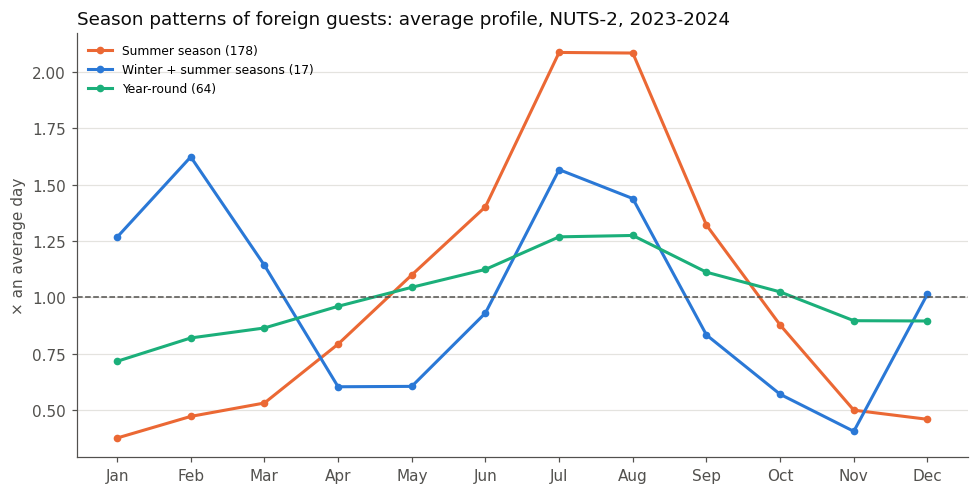

NUTS-2 regions by pattern and amplitude, 2023-2024:


GiniClass                         Low  Medium  High  All
row_0    SeasonPattern                                  
Domestic Summer season              0     120    43  163
         Winter + summer seasons    0      10     3   13
         Year-round                87       0     0   87
Foreign  Summer season              0      96    82  178
         Winter + summer seasons    0      13     4   17
         Year-round                64       0     0   64
Total    Summer season              0     116    59  175
         Winter + summer seasons    0      15     1   16
         Year-round                77       0     0   77
All                               228     370   192  790

In [6]:
seasonal = idx["SeasonCount"] != "No clear season"
dev = fac - 1
unit = dev.div(np.sqrt((dev ** 2).sum(axis=1)), axis=0)          # shape only

def silhouette_values(D, labels):
    s = []
    for i in range(len(labels)):
        same = labels == labels[i]; same[i] = False
        a = D[i, same].mean() if same.any() else 0.0
        b = min(D[i, labels == c].mean() for c in set(labels) if c != labels[i])
        s.append((b - a) / max(a, b))
    return np.array(s)

base_keys = [k for k in unit.index if k[1] == "Foreign" and k[2] == "2023-2024"
             and regions.at[k[0], "NUTSLevel"] == 2 and seasonal.loc[k]]
Xb = unit.loc[base_keys].to_numpy()
Zw, Db = linkage(Xb, method="ward"), squareform(pdist(Xb))
sil = {k: silhouette_values(Db, fcluster(Zw, k, "maxclust")).mean() for k in range(3, 9)}
display(pd.Series(sil, name="mean silhouette (foreign, NUTS-2)").round(3).to_frame().T)
K_BEST = max(sil, key=sil.get)
lab = fcluster(Zw, K_BEST, "maxclust")
MIN_GROUP = 5


def name_of(c):
    if c[["December", "January", "February"]].mean() >= 1:
        return "Winter + summer seasons" if c[["July", "August"]].mean() >= 1 else "Winter season"
    return "Summer season"


PATTERNS = ["Summer season", "Winter + summer seasons", "Winter season", "Year-round"]
names_b = fac.loc[base_keys].reset_index(drop=True).groupby(lab).mean().apply(name_of, axis=1).reindex(lab).to_numpy()
small = [n for n in set(names_b) if (names_b == n).sum() < MIN_GROUP]
for n in small:
    print(f"'{n}' has only {(names_b == n).sum()} regions: folded into the nearest pattern")
keep = ~np.isin(names_b, small)
centres_unit = pd.DataFrame(Xb, columns=MONTH_NAMES)[keep].groupby(names_b[keep]).mean()

# Assign every seasonal profile to the nearest centre (Euclidean distance on the unit-shape vectors).
C_ = centres_unit.to_numpy()
nearest = np.argmin(((unit[seasonal].to_numpy()[:, None, :] - C_[None, :, :]) ** 2).sum(axis=2), axis=1)
pat = pd.Series("Year-round", index=idx.index)
pat[seasonal] = [centres_unit.index[j] for j in nearest]
idx["SeasonPattern"] = pd.Categorical(pat, categories=PATTERNS)
idx["GiniClass"] = pd.Categorical(pd.cut(idx["Gini"], [0, 0.15, 0.33, 1.01], right=False, labels=["Low", "Medium", "High"]),
                                       categories=["Low", "Medium", "High"])
final_b = idx.loc[base_keys, "SeasonPattern"].astype(str).to_numpy()
print(f"{K_BEST} shape groups -> patterns {sorted(set(final_b))}")
centres_fac = fac.loc[base_keys].reset_index(drop=True).groupby(final_b).mean()
fig, ax = plt.subplots(figsize=(9, 4.6), dpi=110)
COLORS = {"Summer season": "#eb6834", "Winter + summer seasons": "#2a78d6", "Winter season": "#6b4fbb", "Year-round": "#1baf7a"}
for k, cf in centres_fac.iterrows():
    ax.plot(range(12), cf.values, color=COLORS[k], lw=2, marker="o", ms=4, label=f"{k} ({(final_b == k).sum()})")
yr = fac.loc[[k for k in fac.index if k[1] == "Foreign" and k[2] == "2023-2024" and regions.at[k[0], "NUTSLevel"] == 2 and not seasonal.loc[k]]]
ax.plot(range(12), yr.mean().values, color=COLORS["Year-round"], lw=2, marker="o", ms=4, label=f"Year-round ({len(yr)})")
ax.axhline(1, color=MUTED, lw=1, ls="--"); ax.set_xticks(range(12), SHORT)
style(ax, "Season patterns of foreign guests: average profile, NUTS-2, 2023-2024", "× an average day")
ax.legend(frameon=False, fontsize=8, loc="upper left"); plt.tight_layout(); plt.show()

tab = idx.xs("2023-2024", level="Period")
tab = tab[tab.index.get_level_values("NUTSCode").map(regions["NUTSLevel"]) == 2]
print("NUTS-2 regions by pattern and amplitude, 2023-2024:")
display(pd.crosstab([tab.index.get_level_values("ResidenceCountry"), tab["SeasonPattern"]], tab["GiniClass"], margins=True))

## B6. Intensity and density

Defined as in Stage 3; they need population and area (Stage 1, step 5b).

* **Intensity** = nights a year ÷ residents; **Density** = nights a year ÷ km². For `2023-2024`: average annual nights ÷ average population.
* **PeakIntensity** = nights per day in the busiest month ÷ residents × 1,000 (guests per 1,000 inhabitants on an average night of the busiest month); **PeakDensity** = the same ÷ km². For `2023-2024`: the busiest month of the average nights-per-day profile of the usable years ÷ their average population.

These describe pressure, not seasonality, and are only computed for usable series (A1); Stage 3, Part 1 computes annual intensity and density for every region from the annual totals.

In [7]:
pop_y = df.drop_duplicates(["NUTSCode", "Year"]).set_index(["NUTSCode", "Year"])["Population"]
area_r = df.drop_duplicates("NUTSCode").set_index("NUTSCode")["AreaKm2"]
ok_ = npd[volume_ok]
codes_, years_ = ok_.index.get_level_values("NUTSCode"), ok_.index.get_level_values("Year")
pop_ = pop_y.reindex(list(zip(codes_, years_))).to_numpy()
single_ = pd.DataFrame({"Intensity": annual.reindex(ok_.index).to_numpy() / pop_, "Density": annual.reindex(ok_.index).to_numpy() / area_r.reindex(codes_).to_numpy(),
                        "PeakIntensity": ok_.max(axis=1).to_numpy() / pop_ * 1000, "PeakDensity": ok_.max(axis=1).to_numpy() / area_r.reindex(codes_).to_numpy()},
                       index=ok_.index)
single_.index = single_.index.set_levels(single_.index.levels[1].astype(str), level="Year")
single_ = single_.reorder_levels(["NUTSCode", "ResidenceCountry", "Year"]).rename_axis(["NUTSCode", "ResidenceCountry", "Period"])
g_ = ok_.groupby(level=["NUTSCode", "ResidenceCountry"])
pop_avg = pd.Series(pop_, index=ok_.index).groupby(level=["NUTSCode", "ResidenceCountry"]).mean()
area_avg = area_r.reindex(g_.mean().index.get_level_values("NUTSCode")).to_numpy()
avg_ = pd.DataFrame({"Intensity": annual.reindex(ok_.index).groupby(level=["NUTSCode", "ResidenceCountry"]).mean() / pop_avg,
                     "Density": annual.reindex(ok_.index).groupby(level=["NUTSCode", "ResidenceCountry"]).mean() / area_avg,
                     "PeakIntensity": g_.mean().max(axis=1) / pop_avg * 1000, "PeakDensity": g_.mean().max(axis=1) / area_avg})
avg_ = avg_.assign(Period="2023-2024").set_index("Period", append=True)
idx = idx.join(pd.concat([single_, avg_]).sort_index().round({"Intensity": 2, "Density": 1, "PeakIntensity": 2, "PeakDensity": 3}))
t_ = idx.xs(("Total", "2023-2024"), level=["ResidenceCountry", "Period"])
t_ = t_[t_.index.map(regions["NUTSLevel"]) == 2]
print(f"NUTS-2, all guests, 2023-2024: median intensity {t_['Intensity'].median():.1f} nights per inhabitant, density {t_['Density'].median():,.0f} per km²")
display(t_.nlargest(5, "PeakIntensity").assign(Region=lambda x: x.index.map(regions["Region"]))[["Region", "Intensity", "Density", "PeakIntensity", "PeakDensity", "PeakMonth"]])

NUTS-2, all guests, 2023-2024: median intensity 4.8 nights per inhabitant, density 668 per km²


,Region,Intensity,Density,PeakIntensity,PeakDensity,PeakMonth
NUTSCode,,,,,,
EL42,Notio Aigaio,122.33,7518.4,825.95,50.761,August
EL62,Ionia Nisia,100.24,8754.3,776.88,67.845,August
HR03,Jadranska Hrvatska,67.36,3555.9,650.52,34.340,August
EL43,Kriti,55.38,4126.6,370.63,27.615,August
ITH1,Provincia Autonoma di Bolzano/Bozen,68.24,4942.7,357.45,25.890,August


# C. Foreign guests

## C1. Foreign share

**PrcForeign** = foreign ÷ all nights (annual, per period). **ForeignGroup**: *Mainly domestic* < 40%, *Mixed* 40–70%, *Mainly foreign* ≥ 70% (unchanged from the platform version, compared below with the terciles of this dataset).

In [8]:
ann = annual.unstack("ResidenceCountry")
fs = (100 * ann["Foreign"] / ann["Total"]).rename("PrcForeign")
fs_y = fs.copy(); fs_y.index = fs_y.index.set_levels(fs_y.index.levels[1].astype(str), level="Year")
fs_avg = (100 * ann["Foreign"].groupby(level="NUTSCode").sum() / ann["Total"].groupby(level="NUTSCode").sum())
foreign_share = pd.concat([fs_y.rename_axis(["NUTSCode", "Period"]),
                           fs_avg.to_frame("PrcForeign").assign(Period="2023-2024").set_index("Period", append=True)["PrcForeign"]]).round(2)
FG = ["Mainly domestic", "Mixed", "Mainly foreign"]
foreign_group = pd.cut(foreign_share, [-np.inf, 40, 70, np.inf], right=False, labels=FG)
x_ = foreign_share.xs("2023-2024", level="Period")
x_ = x_[x_.index.map(regions["NUTSLevel"]) == 2]
print(f"NUTS-2, 2023-2024: terciles of the foreign share {np.percentile(x_, 100/3):.1f} / {np.percentile(x_, 200/3):.1f}%;",
      foreign_group.xs("2023-2024", level="Period").reindex(x_.index).value_counts().reindex(FG).to_dict())

NUTS-2, 2023-2024: terciles of the foreign share 21.0 / 45.3%; {'Mainly domestic': 167, 'Mixed': 70, 'Mainly foreign': 31}


## C2. What would more foreign guests do?

**(a) Gini decomposition — the main measure** (Lerman & Yitzhaki 1985; Fernández-Morales et al. 2016): total Gini = Σ share × Gini correlation × own Gini over the domestic and foreign segments. For the foreign segment: `S_F`, `G_F`, `GiniCorrF` (Γ_F), and

* **`RME_F`** = S_F·Γ_F·G_F / G − S_F: relative marginal effect — the % change in the region's Gini when every month's foreign nights grow by 1% (a proportional increase that keeps today's foreign timing);
* **`ShareNights`** = 100·S_F and **`ShareSeasonality`** = 100·S_F·Γ_F·G_F / G — the foreign shares of the region's nights and of its Gini. `ShareSeasonality − ShareNights` = 100·RME_F; it can exceed 100 when the domestic contribution is negative (`GiniCorrD` < 0: domestic guests busiest in the region's quiet months);

**`ForeignEffectOutcome`**: **Flatten** (RME_F ≤ −0.02), **Sharpen** (≥ +0.02), **Little effect** (in between, or the sign differs between 2023 and 2024). ±0.02 is Fernández-Morales et al.'s cut-off. The paper's further split of *Flatten* into "flatter" and "off-peak" demand, and its *Neutral* type, are not used as classes: R5 shows that "off-peak" is not stable between years and that "neutral" mostly means few foreign guests.

**(b) Timing counterfactual — a check.** Index of all nights minus the index if the foreign nights kept their total but followed the domestic monthly profile, with Gini (`ForeignTimingEffectGini`; R4 repeats it with S_R as a robustness check). Positive = today's foreign timing sharpens the year. **`EffectPerShare`** = effect ÷ S_F: the effect grows with the foreign share almost by construction; dividing by it shows how different foreign timing is from domestic timing.

**(c) Class from (b)** (`ForeignTimingClass`): *Sharpens* / *Smooths* = the 2023–2024 value beyond ±δ **and** the same sign in 2023 and 2024; otherwise *No clear effect*. δ = max(the effect's own year-to-year noise, a smallest effect worth reporting: 0.01 Gini points). Regions with one usable year only are classed on the ±δ rule alone.

Both guest groups need a usable series (A1) in the same year.

In [9]:
def gini_corr(x, y):
    """Gini correlation of x with y: cov(x, rank of y) / cov(x, rank of x)."""
    rx = np.empty(T); rx[np.argsort(x, kind="stable")] = np.arange(1, T + 1)
    ry = np.empty(T); ry[np.argsort(y, kind="stable")] = np.arange(1, T + 1)
    return np.cov(x, ry, bias=True)[0, 1] / np.cov(x, rx, bias=True)[0, 1]

def effects(dv, fv):
    """dv, fv: domestic and foreign nights per day by month (12 values each)."""
    y = dv + fv
    f_cf = fv.sum() * dv / dv.sum()                                   # foreign nights, domestic timing
    G, GF, GD = gini(y), gini(fv), gini(dv)
    SF = fv.sum() / y.sum()
    GC = gini_corr(fv, y)
    GCd = gini_corr(dv, y)
    SFxs = SF * GC * GF / G
    assert abs(G - ((1 - SF) * GCd * GD + SF * GC * GF)) < 1e-9          # decomposition holds exactly
    return {"ForeignTimingEffectSR": s_r(y) - s_r(dv + f_cf), "ForeignTimingEffectGini": G - gini(dv + f_cf),
            "G_Y": G, "S_F": SF, "G_F": GF, "G_D": GD, "GiniCorrF": GC, "GiniCorrD": GCd, "RME_F": SFxs - SF,
            "ShareNights": 100 * SF, "ShareSeasonality": 100 * SFxs}

ok_d = volume_ok.xs("Domestic", level="ResidenceCountry"); ok_f = volume_ok.xs("Foreign", level="ResidenceCountry")
both_ok = ok_d & ok_f.reindex(ok_d.index, fill_value=False)
pd_dom, pd_for = npd.xs("Domestic", level="ResidenceCountry"), npd.xs("Foreign", level="ResidenceCountry")

rows = []
for (code, year) in both_ok[both_ok].index:
    rows.append({"NUTSCode": code, "Period": str(year), **effects(pd_dom.loc[(code, year)].to_numpy(), pd_for.loc[(code, year)].to_numpy())})
# 2023-2024: average nights per day of the usable years (both groups usable in the same years)
for code, g in both_ok[both_ok].groupby(level="NUTSCode"):
    yrs = g.index.get_level_values("Year")
    dv = pd_dom.loc[[(code, y) for y in yrs]].to_numpy().mean(axis=0)
    fv = pd_for.loc[[(code, y) for y in yrs]].to_numpy().mean(axis=0)
    rows.append({"NUTSCode": code, "Period": "2023-2024", "YearsUsed": len(yrs), **effects(dv, fv)})
fe = pd.DataFrame(rows).set_index(["NUTSCode", "Period"]).sort_index()

# Noise of the effect itself: median |2024 - 2023| across regions with both years.
wy = fe["ForeignTimingEffectSR"].unstack("Period")[["2023", "2024"]].dropna()
DELTA = float((wy["2024"] - wy["2023"]).abs().median())
wyg = fe["ForeignTimingEffectGini"].unstack("Period")[["2023", "2024"]].dropna()
DELTA_G = float((wyg["2024"] - wyg["2023"]).abs().median())
print(f"noise of the effect (median |2024 - 2023|): S_R {DELTA:.4f}, Gini {DELTA_G:.4f}")

MIN_EFFECT = {"ForeignTimingEffectSR": 0.01, "ForeignTimingEffectGini": 0.01}   # S_R: robustness only (R4)
def noise(col):
    w_ = fe[col].unstack("Period")[["2023", "2024"]].dropna()
    return float((w_["2024"] - w_["2023"]).abs().median())
DELTAS = {c: max(noise(c), m) for c, m in MIN_EFFECT.items()}
print("thresholds delta = max(noise, smallest effect):", {c: (round(noise(c), 4), round(d_, 4)) for c, d_ in DELTAS.items()})

def classify(effect_col, delta, labels=("Smooths", "No clear effect", "Sharpens")):
    e = fe[effect_col]
    w = e.unstack("Period")
    same_sign = np.sign(w["2023"]) == np.sign(w["2024"])
    stable = same_sign.where(w[["2023", "2024"]].notna().all(axis=1), True)      # one usable year: sign rule not applicable
    cls = pd.Series(labels[1], index=e.index)
    for code, per in e.index:
        v = e.loc[(code, per)]
        ok_sign = bool(stable.get(code, True)) if per == "2023-2024" else True
        if v > delta and ok_sign:
            cls.loc[(code, per)] = labels[2]
        elif v < -delta and ok_sign:
            cls.loc[(code, per)] = labels[0]
    return pd.Categorical(cls, categories=list(labels))
fe["ForeignTimingClass"] = classify("ForeignTimingEffectGini", DELTAS["ForeignTimingEffectGini"])

# Main outcome: RME with the paper's cut-off of +/-0.02 and a stable sign.
OUTCOMES = ["Flatten", "Little effect", "Sharpen"]
fe["ForeignEffectOutcome"] = classify("RME_F", 0.02, tuple(OUTCOMES))
fe["EffectPerShare"] = fe["ForeignTimingEffectGini"] / fe["S_F"]
fe = fe.round(4)

n2e = fe.xs("2023-2024", level="Period"); n2e = n2e[n2e.index.map(regions["NUTSLevel"]) == 2]
print(f"NUTS-2 regions with both guest groups usable: {len(n2e)}")
print("Main outcome (RME) against today's timing class (Gini):")
display(pd.crosstab(n2e["ForeignEffectOutcome"], n2e["ForeignTimingClass"], margins=True))
print(f"Foreign share of seasonality above the foreign share of nights in {(n2e['ShareSeasonality'] > n2e['ShareNights']).sum()} of {len(n2e)} regions; "
      f"above 100% (negative domestic Gini correlation): {', '.join(regions.loc[n2e.index[n2e['ShareSeasonality'] > 100], 'Region'])}")

noise of the effect (median |2024 - 2023|): S_R 0.0037, Gini 0.0035
thresholds delta = max(noise, smallest effect): {'ForeignTimingEffectSR': (0.0037, 0.01), 'ForeignTimingEffectGini': (0.0035, 0.01)}


NUTS-2 regions with both guest groups usable: 257
Main outcome (RME) against today's timing class (Gini):


ForeignTimingClass,Smooths,No clear effect,Sharpens,All
ForeignEffectOutcome,,,,
Flatten,45,12,0,57
Little effect,2,56,5,63
Sharpen,2,15,120,137
All,49,83,125,257


Foreign share of seasonality above the foreign share of nights in 176 of 257 regions; above 100% (negative domestic Gini correlation): Grad Zagreb, Sjeverna Hrvatska


# D. Geography of the regions

The residents' shares of Stage 1 (cities, rural, coastal, inland mountain, island municipalities), passed on unchanged. Stage 3 uses them as shares in the regression and with simple cut-offs in the pattern table (50%+ = predominantly coastal / island / inland mountain / rural; rural 20% or less = urban). They describe where people live, not where guests stay.

In [10]:
geo = df.drop_duplicates("NUTSCode").set_index("NUTSCode")[["PrcCities", "PrcRural", "PrcCoastal", "PrcInlandMountain", "PrcIsland"]]
geo[regions["NUTSLevel"].reindex(geo.index) == 2].describe().round(1)

,PrcCities,PrcRural,PrcCoastal,PrcInlandMountain,PrcIsland
count,260.0,260.0,260.0,257.0,258.0
mean,32.4,29.5,25.8,18.1,8.1
std,23.4,18.7,35.2,32.2,27.3
min,0.0,0.0,0.0,0.0,0.0
25%,17.1,14.2,0.0,0.0,0.0
50%,27.4,30.2,0.0,0.0,0.0
75%,43.3,43.3,51.9,21.3,0.0
max,100.0,100.0,100.0,100.0,100.0


# E. Save

In [11]:
yu = years_used.rename("YearsUsed").reset_index().assign(Period="2023-2024").set_index(["NUTSCode", "ResidenceCountry", "Period"])
out = idx.join(yu)
out["YearsUsed"] = out["YearsUsed"].fillna(1).astype(int)
nights_y = annual.copy(); nights_y.index = nights_y.index.set_levels(nights_y.index.levels[1].astype(str), level="Year")
nights_y = nights_y.reorder_levels(["NUTSCode", "ResidenceCountry", "Year"]).rename_axis(["NUTSCode", "ResidenceCountry", "Period"])
ok_y = volume_ok.copy(); ok_y.index = ok_y.index.set_levels(ok_y.index.levels[1].astype(str), level="Year")
ok_y = ok_y.reorder_levels(["NUTSCode", "ResidenceCountry", "Year"]).rename_axis(["NUTSCode", "ResidenceCountry", "Period"])
avg_n = nights_y[ok_y.reindex(nights_y.index, fill_value=False)].groupby(level=["NUTSCode", "ResidenceCountry"]).mean()
avg_n = avg_n.to_frame("Nights").assign(Period="2023-2024").set_index("Period", append=True)["Nights"]
out["Nights"] = pd.concat([nights_y, avg_n]).reindex(out.index).round(0)
lr = low_rel.copy(); lr.index = lr.index.set_levels(lr.index.levels[1].astype(str), level="Year")
lr = lr.reorder_levels(["NUTSCode", "ResidenceCountry", "Year"]).rename_axis(["NUTSCode", "ResidenceCountry", "Period"])
lr_any = lr.groupby(level=["NUTSCode", "ResidenceCountry"]).any().to_frame("x").assign(Period="2023-2024").set_index("Period", append=True)["x"]
out["LowReliability"] = pd.concat([lr, lr_any]).reindex(out.index).fillna(False).astype(int)
out = out.reset_index()
out = out.merge(regions, left_on="NUTSCode", right_index=True)
out["PrcForeign"] = [foreign_share.get((c, p), np.nan) for c, p in zip(out["NUTSCode"], out["Period"])]
out["ForeignGroup"] = pd.Categorical(pd.cut(out["PrcForeign"], [-np.inf, 40, 70, np.inf], right=False, labels=FG), categories=FG)
out = out.merge(geo, left_on="NUTSCode", right_index=True, how="left")
COLS = ["Region", "NUTSCode", "NUTSLevel", "ParentRegion", "Country", "ResidenceCountry", "Period", "YearsUsed", "Nights", "LowReliability",
        "Gini", "GiniClass", "SR", "SpreadRatio", "SeasonCount", "Season75", "PeakMonth", "SeasonPattern",
        "Intensity", "Density", "PeakIntensity", "PeakDensity", "PrcForeign", "ForeignGroup",
        "PrcCities", "PrcRural", "PrcCoastal", "PrcInlandMountain", "PrcIsland"]
out = out[COLS].sort_values(["Country", "NUTSCode", "ResidenceCountry", "Period"])
import os
os.makedirs("data/ready", exist_ok=True)
out.to_csv("data/ready/tour_occ_nin2m_indices.csv", index=False, encoding="utf-8-sig")

def long_(w, name):
    return w.rename_axis(columns="Month").reset_index().melt(id_vars=["NUTSCode", "ResidenceCountry", "Period"], var_name="Month", value_name=name)
KP = ["NUTSCode", "ResidenceCountry", "Period", "Month"]
pr = long_(profiles, "Share").merge(long_(fac, "Factor"), on=KP).merge(long_(prc75, "Prc75Flag"), on=KP)
pr["Month"] = pd.Categorical(pr["Month"], categories=MONTH_NAMES, ordered=True)
pr = pr.sort_values(KP)
pr["Share"], pr["Factor"] = pr["Share"].round(5), pr["Factor"].round(4)
pr.to_csv("data/ready/tour_occ_nin2m_profiles.csv", index=False, encoding="utf-8-sig")

fe_out = fe.reset_index().merge(regions[["Region", "NUTSLevel", "Country"]], left_on="NUTSCode", right_index=True)
fe_out["YearsUsed"] = fe_out["YearsUsed"].fillna(1).astype(int)
fe_out = fe_out[["Region", "NUTSCode", "NUTSLevel", "Country", "Period", "YearsUsed", "G_Y", "S_F", "G_F", "G_D", "GiniCorrF", "GiniCorrD",
                 "RME_F", "ShareNights", "ShareSeasonality", "ForeignEffectOutcome", "ForeignTimingEffectGini", "EffectPerShare", "ForeignTimingClass"]]
fe_out.to_csv("data/ready/tour_occ_nin2m_foreign_effect.csv", index=False, encoding="utf-8-sig")
print(f"indices: {len(out):,} rows x {out.shape[1]}; profiles: {len(pr):,} rows; foreign effect: {len(fe_out):,} rows")
print(f"constants used: MIN_NIGHTS={MIN_NIGHTS:,}, K_BEST={K_BEST}, deltas={ {k: round(v, 4) for k, v in DELTAS.items()} }")

indices: 3,549 rows x 29; profiles: 42,588 rows; foreign effect: 1,159 rows
constants used: MIN_NIGHTS=100,000, K_BEST=3, deltas={'ForeignTimingEffectSR': 0.01, 'ForeignTimingEffectGini': 0.01}


In [12]:
chk = pd.read_csv("data/ready/tour_occ_nin2m_indices.csv", encoding="utf-8-sig", keep_default_na=False, na_values=[""])
chk_fe = pd.read_csv("data/ready/tour_occ_nin2m_foreign_effect.csv", encoding="utf-8-sig", keep_default_na=False, na_values=[""])
checks = {
    "unique region x group x period": not chk.duplicated(["NUTSCode", "ResidenceCountry", "Period"]).any(),
    "Gini and S_R in range": chk["Gini"].between(0, 11 / 12).all() and chk["SR"].between(0, 1).all(),
    "profiles sum to 1": pr.groupby(["NUTSCode", "ResidenceCountry", "Period"])["Share"].sum().sub(1).abs().lt(1e-3).all(),
    "Season75 = flagged months": (pr.groupby(["NUTSCode", "ResidenceCountry", "Period"])["Prc75Flag"].sum()
                                  .reindex(chk.set_index(["NUTSCode", "ResidenceCountry", "Period"]).index).values == chk["Season75"].values).all(),
    "no confidential month used": not chk.merge(flags.reset_index().assign(Period=lambda x: x["Year"].astype(str)),
                                                on=["NUTSCode", "ResidenceCountry", "Period"])["C"].any(),
    "every pattern named": chk["SeasonPattern"].notna().all(),
    "foreign share 0-100": chk["PrcForeign"].dropna().between(0, 100).all(),
    "S_F in 0-1": chk_fe["S_F"].between(0, 1).all(),
}
display(pd.Series(checks, name="passed").to_frame())
assert all(checks.values())

,passed
unique region x group x period,True
Gini and S_R in range,True
profiles sum to 1,True
Season75 = flagged months,True
no confidential month used,True
every pattern named,True
foreign share 0-100,True
S_F in 0-1,True


# Appendix — robustness

* **R1** — what the calendar adjustment changes;
* **R2** — are the patterns stable between 2023 and 2024, and how distinct are they;
* **R3** — sensitivity of the season count (SpreadRatio cut-offs; the run rule used as a check);
* **R4** — the timing classes: noise, sign stability, Gini vs S_R;
* **R5** — why three RME outcomes and not the paper's four types.

In [13]:
# R1. Nights per day vs monthly totals (NUTS-2, all guest groups, 2023-2024 average profiles)
raw_share = nights[volume_ok].div(nights[volume_ok].sum(axis=1), axis=0).groupby(level=["NUTSCode", "ResidenceCountry"]).mean()
cmp = pd.DataFrame({"SR_per_day": [s_r(r) for r in avg.to_numpy()], "SR_monthly": [s_r(r) for r in raw_share.reindex(avg.index).to_numpy()],
                    "Gini_per_day": [gini(r) for r in avg.to_numpy()], "Gini_monthly": [gini(r) for r in raw_share.reindex(avg.index).to_numpy()],
                    "Feb_per_day": avg["February"].to_numpy() * T, "Feb_monthly": raw_share.reindex(avg.index)["February"].to_numpy() * T},
                   index=avg.index)
cmp = cmp[cmp.index.get_level_values("NUTSCode").map(regions["NUTSLevel"]) == 2]
print("R1. Effect of the calendar adjustment (NUTS-2, 2023-2024 profiles):")
display(pd.DataFrame({"median change": [(cmp["SR_per_day"] - cmp["SR_monthly"]).median(), (cmp["Gini_per_day"] - cmp["Gini_monthly"]).median(),
                                        (cmp["Feb_per_day"] - cmp["Feb_monthly"]).median()],
                      "max |change|": [(cmp["SR_per_day"] - cmp["SR_monthly"]).abs().max(), (cmp["Gini_per_day"] - cmp["Gini_monthly"]).abs().max(),
                                       (cmp["Feb_per_day"] - cmp["Feb_monthly"]).abs().max()]},
                     index=["S_R", "Gini", "February factor"]).round(4))
print(f"rank correlation S_R per day ~ monthly: {cmp['SR_per_day'].corr(cmp['SR_monthly'], method='spearman'):.4f}")

R1. Effect of the calendar adjustment (NUTS-2, 2023-2024 profiles):


,median change,max |change|
S_R,-0.0034,0.0082
Gini,-0.0034,0.0075
February factor,0.0452,0.1408


rank correlation S_R per day ~ monthly: 0.9998


In [14]:
# R2. Pattern stability and distinctness
pp = idx["SeasonPattern"].unstack("Period")
pp = pp[pp.index.get_level_values("NUTSCode").map(regions["NUTSLevel"]) == 2].dropna()
print("R2a. Share of NUTS-2 profiles with the same pattern in 2023 and 2024, by guest group:")
display((pp["2023"] == pp["2024"]).groupby(level="ResidenceCountry").mean().round(2).to_frame("same pattern"))
print("     ... by 2023-2024 pattern (all guest groups):")
display((pp["2023"] == pp["2024"]).groupby(pp["2023-2024"], observed=True).agg(["size", "mean"]).round(2))
sv = silhouette_values(Db, final_b)
print(f"R2b. Silhouette of the foreign shape groups: mean {sv.mean():.2f} (> 0.5 strong, 0.25-0.5 reasonable, < 0.25 weak / a continuum)")
display(pd.Series(sv).groupby(final_b).agg(["size", "mean"]).round(2))

R2a. Share of NUTS-2 profiles with the same pattern in 2023 and 2024, by guest group:


,same pattern
ResidenceCountry,
Domestic,0.97
Foreign,0.93
Total,0.95


     ... by 2023-2024 pattern (all guest groups):


,size,mean
2023-2024,,
Summer season,507,0.98
Winter + summer seasons,44,0.89
Year-round,224,0.89


R2b. Silhouette of the foreign shape groups: mean 0.60 (> 0.5 strong, 0.25-0.5 reasonable, < 0.25 weak / a continuum)


,size,mean
Summer season,178,0.63
Winter + summer seasons,17,0.31


In [15]:
# R3. Number of seasons: sensitivity of the SpreadRatio cut-offs, and of the run rule used as a check
s3 = idx.xs("2023-2024", level="Period")
s3 = s3[(s3.index.get_level_values("NUTSCode").map(regions["NUTSLevel"]) == 2) & (s3["Gini"] >= 0.15)]
rows3 = {}
for lo in (0.5, 0.6, 0.7):
    for hi in (0.85, 0.9, 0.95):
        r_ = s3["SpreadRatio"]
        rows3[(lo, hi)] = {"two seasons": int((r_ < lo).sum()), "main + secondary": int(((r_ >= lo) & (r_ < hi)).sum()),
                           "one season": int((r_ >= hi).sum())}
print("R3a. NUTS-2 profiles (all guest groups, Gini >= 0.15) by SpreadRatio cut-offs (0.6 / 0.9 used):")
display(pd.DataFrame(rows3).T.rename_axis(["two below", "one from"]))
rows3b = {}
for ratio in (0.15, 0.20, 0.25, 0.33, 0.50):
    sc = pd.Series([season_count(f, g, ratio=ratio) for f, g in zip(fac.to_numpy(), idx["Gini"])], index=idx.index).xs("2023-2024", level="Period").reindex(s3.index)
    rows3b[ratio] = {"two seasons (run rule)": int((sc == "Two seasons").sum()),
                     "of which SpreadRatio < 0.9": int(((sc == "Two seasons") & (s3["SpreadRatio"] < 0.9)).sum())}
print("R3b. Run rule: share of the larger season's excess needed for the smaller one (0.25 in B4):")
display(pd.DataFrame(rows3b).T)

R3a. NUTS-2 profiles (all guest groups, Gini >= 0.15) by SpreadRatio cut-offs (0.6 / 0.9 used):


two seasons  main + secondary  one season
two below one from                                           
0.5       0.85                5                61         496
          0.90                5                70         487
          0.95                5               107         450
0.6       0.85               30                36         496
          0.90               30                45         487
          0.95               30                82         450
0.7       0.85               38                28         496
          0.90               38                37         487
          0.95               38                74         450

R3b. Run rule: share of the larger season's excess needed for the smaller one (0.25 in B4):


,two seasons (run rule),of which SpreadRatio < 0.9
0.15,44,43
0.20,34,34
0.25,30,30
0.33,27,27
0.50,16,16


In [16]:
# R4. Foreign effect: noise, sign stability and agreement of the two indices
w4 = fe["ForeignTimingEffectGini"].unstack("Period")[["2023", "2024"]].dropna()
w4 = w4[w4.index.map(regions["NUTSLevel"]) == 2]
print(f"R4. NUTS-2 regions with both years: {len(w4)}; rank correlation 2023 ~ 2024 of the Gini effect: "
      f"{w4['2023'].corr(w4['2024'], method='spearman'):.2f}; same sign in {(np.sign(w4['2023']) == np.sign(w4['2024'])).mean():.0%}")
print(f"     noise (Gini) = {DELTA_G:.4f}, delta used = {DELTAS['ForeignTimingEffectGini']:.4f}; regions with |effect| > delta: "
      f"{(n2e['ForeignTimingEffectGini'].abs() > DELTAS['ForeignTimingEffectGini']).mean():.0%}")
for d_ in (0.005, 0.01, 0.02, 0.03):
    v_ = n2e["ForeignTimingEffectGini"]
    print(f"     with delta {d_}: sharpens {(v_ > d_).sum()}, smooths {(v_ < -d_).sum()} (before the sign rule)")
print(f"     rank correlation of the Gini and S_R effects: {n2e['ForeignTimingEffectGini'].corr(n2e['ForeignTimingEffectSR'], method='spearman'):.2f}")
cls_sr = pd.Series(classify("ForeignTimingEffectSR", DELTAS["ForeignTimingEffectSR"]), index=fe.index).xs("2023-2024", level="Period").reindex(n2e.index)
print(f"     classes on Gini and on S_R agree in {(n2e['ForeignTimingClass'].astype(str) == cls_sr.astype(str)).mean():.0%} of regions")

R4. NUTS-2 regions with both years: 251; rank correlation 2023 ~ 2024 of the Gini effect: 0.97; same sign in 92%
     noise (Gini) = 0.0035, delta used = 0.0100; regions with |effect| > delta: 68%
     with delta 0.005: sharpens 134, smooths 65 (before the sign rule)
     with delta 0.01: sharpens 125, smooths 49 (before the sign rule)
     with delta 0.02: sharpens 94, smooths 33 (before the sign rule)
     with delta 0.03: sharpens 72, smooths 21 (before the sign rule)
     rank correlation of the Gini and S_R effects: 0.97
     classes on Gini and on S_R agree in 92% of regions


In [17]:
# R5. The paper's four types in these data: stability and what "neutral" contains
def four_types(r, g_f, g):
    return np.where(r <= -0.02, np.where(g_f < g, "Flatter", "Off-peak"), np.where(r >= 0.02, "Peak-reinforcing", "Neutral"))


w5 = fe.reset_index().pivot_table(index="NUTSCode", columns="Period", values=["RME_F", "G_F", "G_Y", "S_F"])
w5 = w5[w5.index.map(regions["NUTSLevel"]) == 2]
avg5 = pd.Series(four_types(w5["RME_F"]["2023-2024"], w5["G_F"]["2023-2024"], w5["G_Y"]["2023-2024"]), index=w5.index)
both5 = w5["RME_F"][["2023", "2024"]].dropna().index
print("R5a. Share of NUTS-2 regions whose single-year type equals the 2023-2024 type:")
display(pd.DataFrame({y: (pd.Series(four_types(w5["RME_F"][y], w5["G_F"][y], w5["G_Y"][y]), index=w5.index).reindex(both5)
                          == avg5.reindex(both5)).groupby(avg5.reindex(both5)).mean() for y in ("2023", "2024")}).round(2)
        .assign(regions=avg5.reindex(both5).value_counts()))
neutral = w5.index[avg5 == "Neutral"]
sf = w5["S_F"]["2023-2024"].reindex(neutral)
print(f"R5b. 'Neutral' regions: {len(neutral)}; foreign share under 20%: {(sf < 0.2).sum()}; 85% or more ('foreign guests are the season'): "
      f"{(sf >= 0.85).sum()}; in between: {((sf >= 0.2) & (sf < 0.85)).sum()}")
print("=> 'Off-peak' is too small and unstable to be a class, and 'Neutral' mostly means few foreign guests: three outcomes are used (C2).")

R5a. Share of NUTS-2 regions whose single-year type equals the 2023-2024 type:


,2023,2024,regions
Flatter,0.94,0.88,52
Neutral,0.84,0.93,55
Off-peak,0.57,0.57,7
Peak-reinforcing,0.96,0.99,137


R5b. 'Neutral' regions: 59; foreign share under 20%: 34; 85% or more ('foreign guests are the season'): 4; in between: 21
=> 'Off-peak' is too small and unstable to be a class, and 'Neutral' mostly means few foreign guests: three outcomes are used (C2).
